# Desenvolvimento do modelo de Multi Layer Perceptron (MLP) Classifier Binário de duas camadas ocultas
---

Esse notebook mostra o desenvolvimento, de maneira explicada, de um `MLP` de duas camadas. Trará aplicações de `RFE`, limiares relativos à `Sensibilidade`, `Precisão` e `Equilíbrio`.

Será usado `GridSearchCV` para eleger um modelo campeão de cada uma das categorias. Ao final, os campeões terão suas características analisadas

## A) Importando as Bibliotecas e Pacotes a serem usados
---

### 1. Pacotes baixados
---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.feature_selection import RFE
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

### 2. Pacotes Predexan
---

In [2]:
import sys
import os

caminho_predexan = os.path.abspath(os.path.join(os.getcwd(), '../..'))

if caminho_predexan not in sys.path:
    sys.path.append(caminho_predexan)

print(f"Pastas encontradas: {os.listdir(caminho_predexan)}")

import predexan.graficos as pg
import predexan.metricas as pm
import predexan.preproc as pp

Pastas encontradas: ['.ipynb_checkpoints', 'analise_exploratoria_pre_processamento', 'dataset', 'imagens', 'modelos', 'predexan', 'README.md']


## B) Determinando os Dataframes à partir das bases de dados pré-processados
---

### 1. Determinando df_treino
---

In [3]:
df_treino = pd.read_parquet('../../dataset/pre_processado/treino_pre_processado.parquet')
df_treino.info()

<class 'pandas.DataFrame'>
Index: 96822 entries, 0 to 175337
Data columns (total 59 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   duracao_conexao_seg                 96822 non-null  float64
 1   num_pacotes_origem                  96822 non-null  float64
 2   num_pacotes_destino                 96822 non-null  float64
 3   total_bytes_origem                  96822 non-null  float64
 4   total_bytes_destino                 96822 non-null  float64
 5   taxa_pacote                         96822 non-null  float64
 6   carga_origem                        96822 non-null  float64
 7   carga_destino                       96822 non-null  float64
 8   pacotes_perdidos_origem             96822 non-null  float64
 9   pacotes_perdidos_destino            96822 non-null  float64
 10  tempo_medio_pacote_origem           96822 non-null  float64
 11  bytes_por_pacote_destino            96822 non-null  floa

### 2. Determinando df_teste
---

In [4]:
df_teste = pd.read_parquet('../../dataset/pre_processado/teste_pre_processado.parquet')
df_teste.info()

<class 'pandas.DataFrame'>
Index: 49971 entries, 0 to 82328
Data columns (total 57 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   duracao_conexao_seg                 49971 non-null  float64
 1   num_pacotes_origem                  49971 non-null  float64
 2   num_pacotes_destino                 49971 non-null  float64
 3   total_bytes_origem                  49971 non-null  float64
 4   total_bytes_destino                 49971 non-null  float64
 5   taxa_pacote                         49971 non-null  float64
 6   carga_origem                        49971 non-null  float64
 7   carga_destino                       49971 non-null  float64
 8   pacotes_perdidos_origem             49971 non-null  float64
 9   pacotes_perdidos_destino            49971 non-null  float64
 10  tempo_medio_pacote_origem           49971 non-null  float64
 11  bytes_por_pacote_destino            49971 non-null  float

## C) Separando os valores em teste e treino
---

Nessa seção, serão separadas as `features` do `target`, tanto para a base de testes quanto de treino.

Há duas possibilidades claras de `target`, presentes nos datasets, dado o cenário de `Classificação` e `Regressão Logística`: `label`e `categoria_ataque.

A primeira retornaria um diagnóstico apontado se há uma probabilidade alta ou baixa de haver um ataque, de maneira geral. Já a segunda, retornaria a probabilidade de haver um ataque específico dentro de suas dez classes.

A escolha do target se embasa tanto na especialização da resposta, quanto no desempenho e custo computacional do modelo. Dessa forma, ao escolher `label`, a resposta é mais simples, mas continua sendo de grande valor, e o custo computacional é muito inferior. Já a escolha de `categoria_ataque`, traz uma resposta mais especializada e de maior qualidade para o usuário, contudo o custo computacional se mostrou alto.

### 1. Atributos do df_treino
---

In [5]:
# Features
X_treino = df_treino.drop(columns=['label_0', 
                                   'label_1',
                                   'categoria_ataque_Analysis',
                                   'categoria_ataque_Backdoor',
                                   'categoria_ataque_DoS',
                                   'categoria_ataque_Exploits',
                                   'categoria_ataque_Fuzzers',
                                   'categoria_ataque_Generic',
                                   'categoria_ataque_Normal',
                                   'categoria_ataque_Reconnaissance',
                                   'categoria_ataque_Shellcode',
                                   'categoria_ataque_Worms'
                                  ])
print(f'O tipo de X_treino é {type(X_treino)}. Possui {X_treino.shape[1]} features e {X_treino.shape[0]} registros.')
# Target
y_treino = df_treino['label_1'] # Escolhendo somente uma, no caso a de ataque, se torna classificação binária
print(f'O tipo de y_treino é {type(y_treino)}')

O tipo de X_treino é <class 'pandas.DataFrame'>. Possui 47 features e 96822 registros.
O tipo de y_treino é <class 'pandas.Series'>


### 2. Atributos do df_teste
---

In [6]:
# Features
X_teste = df_teste.drop(columns=['label_0', 
                                   'label_1',
                                   'categoria_ataque_Analysis',
                                   'categoria_ataque_Backdoor',
                                   'categoria_ataque_DoS',
                                   'categoria_ataque_Exploits',
                                   'categoria_ataque_Fuzzers',
                                   'categoria_ataque_Generic',
                                   'categoria_ataque_Normal',
                                   'categoria_ataque_Reconnaissance',
                                   'categoria_ataque_Shellcode',
                                   'categoria_ataque_Worms'
                                  ])
print(f'O tipo de X_teste é {type(X_teste)}. Possui {X_teste.shape[1]} features e {X_teste.shape[0]} registros.')
# Target
y_teste = df_teste['label_1'] # Escolhendo somente uma, no caso a de ataque, se torna classificação binária
print(f'O tipo de y_teste é {type(y_teste)}')

O tipo de X_teste é <class 'pandas.DataFrame'>. Possui 45 features e 49971 registros.
O tipo de y_teste é <class 'pandas.Series'>


O dataset de teste possui duas features a menos: `servico_conexao_pop3` e `servico_conexao_ssh`. Desta forma, é necessário adicionar ambas, com os valores iguais a `0.0`:

In [7]:
X_teste = X_teste.reindex(columns=X_treino.columns, fill_value=0.0)

print(f'Agora, o tipo de X_teste é {type(X_teste)}. Possui {X_teste.shape[1]} features e {X_teste.shape[0]} registros.')

Agora, o tipo de X_teste é <class 'pandas.DataFrame'>. Possui 47 features e 49971 registros.


## D) Desenvolvimento dos Modelos de MLP de Classificação de duas camadas sem a aplicação do RFE
---

### 1. Aplicação do PredefinedSplit usando X_treino
---

In [8]:
limite = int(len(X_treino) * 0.8)

# -1 indica dados de treino | 0 indica dados de validação
indices_validacao = np.zeros(X_treino.shape[0])
indices_validacao[:limite] = -1  # Treino
indices_validacao[limite:] = 0   # Validação

# Divisor customizado
pds = PredefinedSplit(test_fold=indices_validacao)

### 2. Criação do modelo base
---

In [9]:
# Grid Search passando o 'pds' no lugar do 'cv'(Cross-Validation)
mlp_base = MLPClassifier(
    max_iter=2000, 
    tol=0.0001,  
    learning_rate='adaptive', 
    alpha=0.001, 
    n_iter_no_change=15, 
    solver="adam", 
    random_state=42, 
    verbose=True
)

#### 2.1. Explicação dos hiperparâmetros
---


- `max_iter=2000`: limite máximo de iterações de treinamento. Se chegar a 2000 voltas, o treinamento para obrigatoriamente, mesmo que não tenha atingido a perfeição.
- `tol=0.0001`: tolerância para melhoria do erro (loss). Se a diferença de erro entre uma iteração e outra for menor do que 0.0001, o Python entende que a rede estabilizou e parou de evoluir significativamente.

- `learning_rate='adaptive'`: comportamento da taxa de aprendizado ao longo do tempo. Enquanto o modelo estiver conseguindo diminuir o erro, ele mantém o passo inicial (0.001). Se o erro parar de cair por duas épocas seguidas, a rede divide a taxa de aprendizado por 5, dando passos menores e mais cautelosos para tentar melhorar.
- `validation_fraction=0.1`: Reserva 10% dos seus dados de treino para usar como validação. A rede treina nos outros 90% e se testa nesses 10% para saber se está realmente aprendendo ou apenas decorando. É com base nessa nota que o `n_iter_no_change` e o `learning_rate='adaptive'` tomam suas decisões.
- `alpha=0.001`: evita o `overfitting` (regularização L2). Penaliza pesos que fiquem grandes demais na rede. Isso força o modelo a se manter simples e impede que ele decore o banco de dados de treino, ajudando-o a funcionar bem com dados novos de verdade. A fórmula de Regularização L2 (ou Ridge) é: $$Loss_{total} = Loss_{original} + \alpha \sum_{i} w_i^2$$
- `n_iter_no_change=15`: número de iterações que a rede vai esperar se a melhora do erro ficar abaixo daquela tolerância (tol). Se por 15 vezes seguidas o modelo não melhorar quase nada, ele aciona o "early stopping" (parada precoce) e encerra o treino para economizar tempo.
- `solver="adam"`: motor matemático que ajusta os pesos da rede otimizando-a. O `adam` é o algoritmo padrão do mercado. Funciona como um piloto automático inteligente que descobre sozinho o melhor caminho para diminuir os erros do modelo de forma rápida e eficiente. A fórmula simplificada de como o adam ajusta o passo a cada iteração $t$ é:$$w_t = w_{t-1} - \frac{\eta}{\sqrt{\hat{v}_t} + \epsilon} \hat{m}_t$$
  $f(x) = \max(0, x)$
- `verbose=True`: exibe na tela do terminal o progresso do erro a cada iteração que passa. Essencial para acompanhar se o modelo está evoluindo ou se travou.
- `random_state=42`: semente de aleatoriedade. Redes neurais começam com pesos aleatórios e embaralham os dados antes de treinar. Definir o número 42 (ou qualquer outro número fixo) garante que a aleatoriedade seja exatamente a mesma toda vez que  rodar o script. Assim, os resultados serão iguais e replicáveis.

### 3. Definição dos parâmetros e instanciação da classe GridSearchCV 
---

In [10]:
parametros = {'hidden_layer_sizes': [(64, 32), (32, 64), (64, 64)], # Arquitetura das camadas (Funil vs Ampulheta vs Simétrica)
              'activation': ['relu', 'tanh'], # Motor matemático de ativação dos neurônios
              'learning_rate_init': [0.001, 0.0005] # Velocidade dos passos iniciais do otimizador Adam
             }

#### 3.1. Explicação dos hiperparâmetros a serem testados
---

1.  `hidden_layer_sizes`: define a arquitetura estrutural da rede neural, determinando tanto a quantidade de camadas ocultas quanto o número de neurônios presentes em cada uma delas. Serão testadas [(64, 32), (32, 64), (64, 64)]: a grade foi desenhada para avaliar o comportamento geométrico do fluxo de informação através de três conceitos distintos:

- **Funil (64, 32)**: Inicia com maior capacidade de abstração e condensa o conhecimento na segunda camada, filtrando ruídos.

- **Ampulheta (32, 64)**: Restringe o fluxo inicialmente para forçar uma representação compacta e expande a dimensionalidade na sequência.

- **Simétrica (64, 64)**: Mantém a capacidade de processamento homogênea ao longo de todo o mapeamento interno.

2.  `activation`: define a função de ativação que será aplicada nas camadas ocultas para introduzir não-linearidade à rede, permitindo que ela aprenda padrões complexos que vão além de uma simples separação linear.

- A **ReLU (Rectified Linear Unit)** converte qualquer valor negativo em zero e mantém os valores positivos inalterados, sendo matematicamente definida por:$$f(x) = \max(0, x)$$.
- A **Tanh (Tangente Hiperbólica)** mapeia os valores de entrada para um intervalo contínuo entre -1 e 1, o que centraliza a média das saídas próximo a zero e costuma estabilizar o aprendizado em dados de segurança de rede. Sua fórmula é:$$f(x) = \tanh(x) = \frac{e^x - e^{-x}}{e^x + e^{-x}}$$.

O Grid Search colocará as duas principais funções da literatura para competir, identificando qual dinâmica matemática se adapta melhor à distribuição estatística das características do tráfego de rede presente no dataset.


3. `learning_rate_init`: define a taxa de aprendizado inicial (tamanho do passo) que o otimizador utiliza para ajustar os pesos dos neurônios. Passos muito grandes podem fazer o algoritmo oscilar e divergir da solução ideal; passos muito pequenos tornam o treinamento extremamente lento e suscetível a travar em mínimos locais. A fórmula de atualização dos pesos baseia-se no gradiente descendente:$$w_{novo} = w_{antigo} - \eta \cdot \frac{\partial \text{Loss}}{\partial w}$$.

Serão testados os valores [0.001, 0.0005]: O valor 0.001 é o padrão ouro do otimizador Adam, mas ao testar o valor ligeiramente menor de 0.0005, o Grid Search avalia se a rede precisa de uma abordagem mais cautelosa e refinada para convergir melhor os dados complexos do dataset **UNSW-NB15**.



#### 3.2. Explicação dos hiperparâmetros do GridSearchCV
---

In [11]:
# cv=pds vai rodar apenas uma vez cada arquitetura
grid_search = GridSearchCV(estimator=mlp_base, param_grid=parametros, scoring='average_precision', cv=pds, n_jobs=4, verbose=2)

- `estimator=mlp_base`: define o algoritmo base que será testado. No caso, indica que o Grid Search aplicará as combinações de parâmetros em cima da estrutura da Rede Neural Multi-Layer Perceptron (MLPClassifier).
- `param_grid=parametros`: o dicionário de busca que contém a grade de opções. Se o dicionário testar, por exemplo, 3 arquiteturas de camadas ocultas e 3 taxas de aprendizado diferentes, o Grid Search multiplicará essas opções para testar de forma exaustiva todas as $3 \times 3 = 9$ combinações possíveis.
- `cv=pds`: estratégia de validação cruzada (Cross-Validation). O pds (objeto PredefinedSplit) indica que os conjuntos de dados de treino e teste/validação já possuem uma divisão fixa pré-definida. Isso faz com que cada arquitetura seja executada apenas uma vez em vez de rodar o padrão de 5 vezes (5-fold), economizando tempo de processamento e respeitando a divisão original do dataset UNSW-NB15.
- `n_jobs=4`: define o nível de paralelismo do processo de busca. Ao configurar o valor como 4, o Python instrui o processador a abrir 4 núcleos de processamento (threads) em paralelo. Isso permite que o computador treine até 4 redes neurais de uma só vez, reduzindo o tempo total do Grid Search em quase $4\times$

### 4. Treino dos modelos com GridSearchCV 
---

In [12]:
pm.imprimir_desempenho(grid_search.fit, X_treino, y_treino)

Fitting 1 folds for each of 12 candidates, totalling 12 fits
Iteration 1, loss = 0.33169707
Iteration 2, loss = 0.24117387
Iteration 3, loss = 0.22584612
Iteration 4, loss = 0.21784212
Iteration 5, loss = 0.21268684
Iteration 6, loss = 0.20809870
Iteration 7, loss = 0.20396407
Iteration 8, loss = 0.20122741
Iteration 9, loss = 0.19804771
Iteration 10, loss = 0.19539987
Iteration 11, loss = 0.19415895
Iteration 12, loss = 0.19217391
Iteration 13, loss = 0.19166790
Iteration 14, loss = 0.19006569
Iteration 15, loss = 0.18896484
Iteration 16, loss = 0.18846224
Iteration 17, loss = 0.18798765
Iteration 18, loss = 0.18700220
Iteration 19, loss = 0.18655422
Iteration 20, loss = 0.18585467
Iteration 21, loss = 0.18545252
Iteration 22, loss = 0.18543080
Iteration 23, loss = 0.18450155
Iteration 24, loss = 0.18442778
Iteration 25, loss = 0.18343214
Iteration 26, loss = 0.18329565
Iteration 27, loss = 0.18328715
Iteration 28, loss = 0.18248099
Iteration 29, loss = 0.18268556
Iteration 30, loss =

GridSearchCV(cv=PredefinedSplit(test_fold=array([-1, -1, ...,  0,  0], shape=(96822,))),
             estimator=MLPClassifier(alpha=0.001, learning_rate='adaptive',
                                     max_iter=2000, n_iter_no_change=15,
                                     random_state=42, verbose=True),
             n_jobs=4,
             param_grid={'activation': ['relu', 'tanh'],
                         'hidden_layer_sizes': [(64, 32), (32, 64), (64, 64)],
                         'learning_rate_init': [0.001, 0.0005]},
             scoring='average_precision', verbose=2)

### 5. Resultado e escolha do modelo campeão
---

In [13]:
print("\nResultado:")
print(f" - Melhor arquitetura encontrada: {grid_search.best_params_['hidden_layer_sizes']}")
print(f" - Melhor ativação encontrada: {grid_search.best_params_['activation']}")
print(f" - Melhor taxa de aprendizado inicial: {grid_search.best_params_['learning_rate_init']}")
print(f" - Acurácia na validação fixa: {grid_search.best_score_:.4f}")


Resultado:
 - Melhor arquitetura encontrada: (64, 32)
 - Melhor ativação encontrada: tanh
 - Melhor taxa de aprendizado inicial: 0.0005
 - Acurácia na validação fixa: 0.9921


In [14]:
modelo_campeao = grid_search.best_estimator_

### 6. Realização das Predições de Teste
---

#### 6.1. Predição Probababilística
---

Para a Predição Probabilística, é usado o método `predict_proba()` na seguinte expressão: `modelo_campeao.predict_proba(X_teste)`

In [15]:
y_predicao_probabilistica_1 = pm.imprimir_desempenho(modelo_campeao.predict_proba, X_teste)[:, 1]


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 31/05/2026 11:52:07

    1. TEMPO: 0.1611s (0.00 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 54.52 MB
        - Diferença líquida de RAM no processo: 26.85 MB
        - Total RAM alocada para o processo: 371.43 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 15.5%

  Execução concluída em: 31/05/2026 11:52:07



#### 6.2. Predição Binária
---

Para a Predição Binária, é usado o método `predict()` na seguinte expressão: `modelo_campeao.predict(X_teste)`

In [16]:
y_predicao_binaria_1 = pm.imprimir_desempenho(modelo_campeao.predict, X_teste)


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 31/05/2026 11:52:07

    1. TEMPO: 0.2019s (0.00 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 54.52 MB
        - Diferença líquida de RAM no processo: 0.00 MB
        - Total RAM alocada para o processo: 371.44 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 21.7%

  Execução concluída em: 31/05/2026 11:52:07



### 7. Desempenho do modelo
---

#### 7.1. Limiar Padrão (0.5)
---

##### 7.1.1. Matriz de Confusão
---

<Axes: >

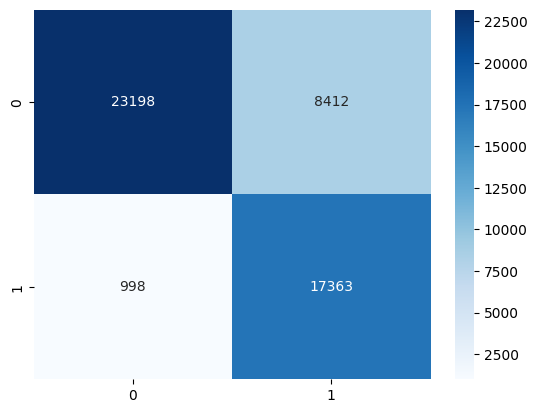

In [17]:
matriz_confusao_1 = confusion_matrix(y_teste, y_predicao_binaria_1)
sns.heatmap(matriz_confusao_1, annot=True, fmt='d', cmap='Blues')

##### 7.1.2. Relatório de Classificação
---

In [18]:
relatorio_classificacao_1 = classification_report(y_teste, y_predicao_binaria_1)
print(relatorio_classificacao_1)

              precision    recall  f1-score   support

         0.0       0.96      0.73      0.83     31610
         1.0       0.67      0.95      0.79     18361

    accuracy                           0.81     49971
   macro avg       0.82      0.84      0.81     49971
weighted avg       0.85      0.81      0.81     49971



##### 7.1.3. Curva ROC-AUC
---

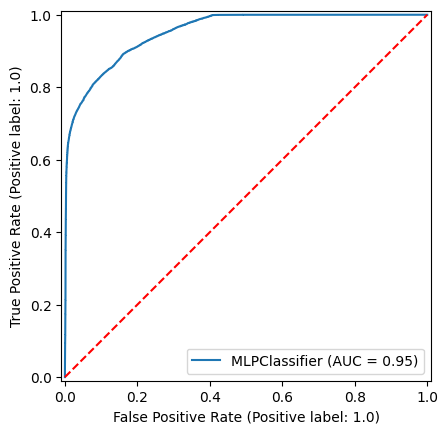

In [19]:
pg.gerar_roc_auc(modelo_campeao, X_teste, y_teste)

##### 7.1.4. Curva Precision-Recall
---

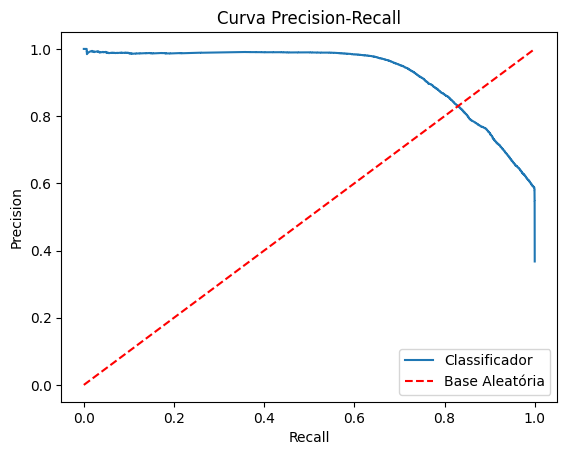

In [20]:
pg.gerar_curva_pr(y_teste, y_predicao_probabilistica_1)

In [21]:
pm.imprimir_prt(y_teste, y_predicao_probabilistica_1, obj_recall=True, meta_recall=0.95, obj_precision=True, meta_precision=0.95, obj_f1=True)


 - Objetivo focado em Recall (meta = 95.0%)
      Limiar ideal a ser usado: 0.4797
      Recall real obtido: 95.00% (Ataques detectados)
      Precision real obtida: 66.62% (Acerto dos alertas disparados)

 - Objetivo focado em Precision (meta >= 95.0%)
      Limiar ideal a ser usado: 0.9202
      Recall real obtido: 70.52% (Ataques detectados)
      Precision real obtida: 95.00% (Acerto dos alertas disparados)

 - Equilíbrio Simétrico (Max F1-Score)
      Limiar ideal: 0.7906
      Recall neste ponto: 80.76% (Ataques detectados)
      Precision neste ponto: 85.83% (Acerto dos alertas)


##### 7.1.5. Curva de Aprendizado
---

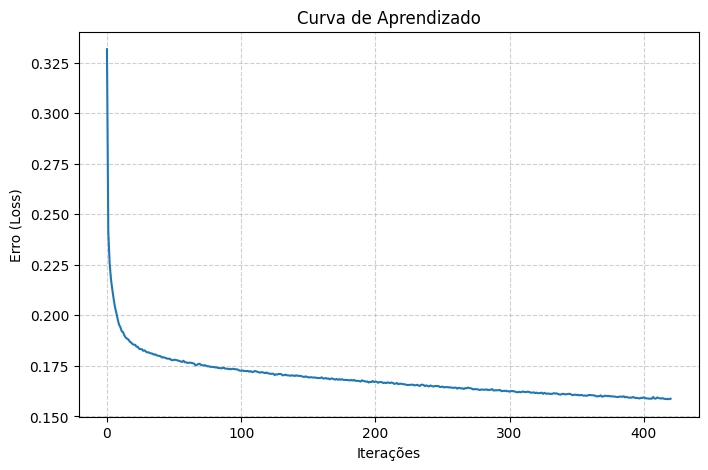

In [22]:
pg.gerar_curva_aprendizado(modelo_campeao)

#### 7.2. Limiar Equilibrado
---

##### 7.2.1. Matriz de Confusão
---

Limiar de equilíbrio do F1-Score entre Recall e Precision:

In [23]:
_, limiar_modelo_campeao, _ = pm.extrair_f1(y_teste, y_predicao_probabilistica_1)
print(limiar_modelo_campeao)

0.7906421155860779


In [24]:
y_predicao_probabilistica_equilibrada_1 = (y_predicao_probabilistica_1 > limiar_modelo_campeao).astype(int)

<Axes: >

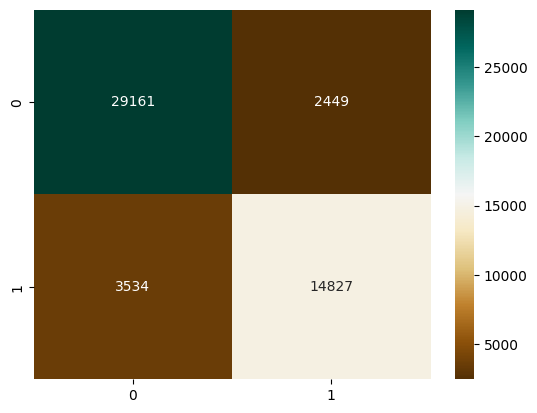

In [25]:
matriz_confusao_equilibrada_1 = confusion_matrix(y_teste, y_predicao_probabilistica_equilibrada_1)
sns.heatmap(matriz_confusao_equilibrada_1, annot=True, fmt='d', cmap='BrBG')

##### 7.2.2. Relatório de Classificação
---

In [26]:
relatorio_classificacao_equilibrado_1 = classification_report(y_teste, y_predicao_probabilistica_equilibrada_1)
print(relatorio_classificacao_equilibrado_1)

              precision    recall  f1-score   support

         0.0       0.89      0.92      0.91     31610
         1.0       0.86      0.81      0.83     18361

    accuracy                           0.88     49971
   macro avg       0.88      0.87      0.87     49971
weighted avg       0.88      0.88      0.88     49971



## E) Desenvolvimento dos Modelo de MLPs de Classificação com RFE + XGBoost Classifier
---

### 1. Aplicação do Recursive Feature Elimination (RFE) para diminuição da dimensionalidade
---

#### 1.1. Instanciamento da classe RFE
---

O objetivo é a diminuição da dimensionalidade, e a escolha das 30 features mais relevantes.

In [27]:
xgb_estimador = XGBClassifier(random_state=42, eval_metric='logloss')

In [28]:
seletor_rfe = RFE(estimator=xgb_estimador, n_features_to_select=30)

#### 1.2. Aplicação do RFE em X_treino
---

In [29]:
X_treino_reduzido = seletor_rfe.fit_transform(X_treino, y_treino)

In [30]:
colunas_originais = X_treino.columns
print(f'Registros e features de treino ANTES da aplicação do RFE:\n - Número de features e registros: {X_treino.shape}\n - Nomes das features:\n{X_treino.columns}\n')
colunas_selecionadas = colunas_originais[seletor_rfe.support_]
print(f'\nRegistros e features de treino DEPOIS da aplicação do RFE:\n - Número de features e registros:  {X_treino_reduzido.shape} \n - Nomes das features:\n{list(colunas_selecionadas)}')

Registros e features de treino ANTES da aplicação do RFE:
 - Número de features e registros: (96822, 47)
 - Nomes das features:
Index(['duracao_conexao_seg', 'num_pacotes_origem', 'num_pacotes_destino',
       'total_bytes_origem', 'total_bytes_destino', 'taxa_pacote',
       'carga_origem', 'carga_destino', 'pacotes_perdidos_origem',
       'pacotes_perdidos_destino', 'tempo_medio_pacote_origem',
       'bytes_por_pacote_destino', 'var_lat_pacotes_origem',
       'var_lat_pacotes_destino', 'tamanho_janela_tcp_origem',
       'num_sequencia_tcp_origem', 'num_sequencia_tcp_destino',
       'tamanho_janela_tcp_destino', 'rtt_handshake_tcp', 'tempo_syn_synack',
       'tempo_synack_ack', 'tamanho_medio_pacotes_origem',
       'tamanho_medio_pacotes_destino', 'profundidade_transacao_http',
       'tamanho_corpo_resposta_http', 'conexoes_recentes_ip_porta_destino',
       'conexoes_recentes_ip_porta_origem', 'ftp_autenticada',
       'num_comandos_ftp', 'num_metodos_http',
       'ip_porta_

In [31]:
type(X_treino_reduzido)

numpy.ndarray

In [32]:
X_treino_reduzido_df = pd.DataFrame(X_treino_reduzido, columns=colunas_selecionadas)
X_treino_reduzido_df.head()

,num_pacotes_origem,total_bytes_origem,total_bytes_destino,carga_origem,carga_destino,pacotes_perdidos_origem,pacotes_perdidos_destino,tempo_medio_pacote_origem,var_lat_pacotes_origem,tamanho_janela_tcp_origem,...,protocolo_rede_udp,servico_conexao_-,servico_conexao_ftp,servico_conexao_ftp-data,servico_conexao_http,servico_conexao_outros,servico_conexao_smtp,estado_conexao_CON,estado_conexao_INT,estado_conexao_outros
0,-0.250,-0.329992,-0.154433,-0.034939,-0.002418,-0.4,-0.333333,-0.054359,-0.337678,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.250,-0.131161,12.130358,-0.044014,0.808271,0.0,2.500000,0.269346,-0.330958,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,-0.125,-0.285714,3.666471,-0.054756,0.083443,-0.2,0.666667,2.568450,3.349831,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.125,-0.175439,0.021139,-0.052917,-0.010829,-0.2,0.166667,1.570283,-0.288459,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.000,-0.214703,-0.126248,-0.043752,-0.009800,0.0,-0.166667,0.241995,0.175293,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [33]:
for feature in X_treino_reduzido_df.columns:
    print(f'\nFeature {feature.upper()}:')
    print(f'\n - Amplitude: de {X_treino_reduzido_df[feature].min()} a {X_treino_reduzido_df[feature].max()}')
    print(f'\n - Magnitude: {X_treino_reduzido_df[feature].max() - X_treino_reduzido_df[feature].min()}\n')


Feature NUM_PACOTES_ORIGEM:

 - Amplitude: de -0.5625 a 600.375

 - Magnitude: 600.9375


Feature TOTAL_BYTES_ORIGEM:

 - Amplitude: de -0.42606516290726815 a 5415.2819548872185

 - Magnitude: 5415.708020050126


Feature TOTAL_BYTES_DESTINO:

 - Amplitude: de -0.20493247210804463 a 4302.6576629477395

 - Magnitude: 4302.862595419848


Feature CARGA_ORIGEM:

 - Amplitude: de -0.057231631081325486 a 9427.744951992034

 - Magnitude: 9427.802183623115


Feature CARGA_DESTINO:

 - Amplitude: de -0.016328903360192524 a 36.700989512499405

 - Magnitude: 36.717318415859594


Feature PACOTES_PERDIDOS_ORIGEM:

 - Amplitude: de -0.4 a 960.2

 - Magnitude: 960.6


Feature PACOTES_PERDIDOS_DESTINO:

 - Amplitude: de -0.3333333333333333 a 913.6666666666666

 - Magnitude: 914.0


Feature TEMPO_MEDIO_PACOTE_ORIGEM:

 - Amplitude: de -0.36133865318408365 a 1065.6872198364367

 - Magnitude: 1066.0485584896207


Feature VAR_LAT_PACOTES_ORIGEM:

 - Amplitude: de -0.34416657687734703 a 313.6919244498777



#### 1.3. Aplicação do RFE em X_teste
---

In [34]:
X_teste_reduzido = seletor_rfe.transform(X_teste)

In [35]:
colunas_originais = X_teste.columns
print(f'Registros e features de treino ANTES da aplicação do RFE:\n - Número de features e registros: {X_teste.shape}\n - Nomes das features: {X_teste.columns}\n')
colunas_selecionadas = colunas_originais[seletor_rfe.support_]
print(f'\nRegistros e features de treino DEPOIS da aplicação do RFE:\n - Número de features e registros:  {X_teste_reduzido.shape} \n - Nomes das features: {list(colunas_selecionadas)}')

Registros e features de treino ANTES da aplicação do PCA:
 - Número de features e registros: (49971, 47)
 - Nomes das features: Index(['duracao_conexao_seg', 'num_pacotes_origem', 'num_pacotes_destino',
       'total_bytes_origem', 'total_bytes_destino', 'taxa_pacote',
       'carga_origem', 'carga_destino', 'pacotes_perdidos_origem',
       'pacotes_perdidos_destino', 'tempo_medio_pacote_origem',
       'bytes_por_pacote_destino', 'var_lat_pacotes_origem',
       'var_lat_pacotes_destino', 'tamanho_janela_tcp_origem',
       'num_sequencia_tcp_origem', 'num_sequencia_tcp_destino',
       'tamanho_janela_tcp_destino', 'rtt_handshake_tcp', 'tempo_syn_synack',
       'tempo_synack_ack', 'tamanho_medio_pacotes_origem',
       'tamanho_medio_pacotes_destino', 'profundidade_transacao_http',
       'tamanho_corpo_resposta_http', 'conexoes_recentes_ip_porta_destino',
       'conexoes_recentes_ip_porta_origem', 'ftp_autenticada',
       'num_comandos_ftp', 'num_metodos_http',
       'ip_porta_

In [36]:
type(X_teste_reduzido)

numpy.ndarray

In [37]:
X_teste_reduzido_df = pd.DataFrame(X_teste_reduzido, columns=colunas_selecionadas)
X_teste_reduzido_df.head()

,num_pacotes_origem,total_bytes_origem,total_bytes_destino,carga_origem,carga_destino,pacotes_perdidos_origem,pacotes_perdidos_destino,tempo_medio_pacote_origem,var_lat_pacotes_origem,tamanho_janela_tcp_origem,...,protocolo_rede_udp,servico_conexao_-,servico_conexao_ftp,servico_conexao_ftp-data,servico_conexao_http,servico_conexao_outros,servico_conexao_smtp,estado_conexao_CON,estado_conexao_INT,estado_conexao_outros
0,-0.5,-0.230576,-0.204932,283.916144,-0.016329,-0.4,-0.333333,-0.361200,-0.344167,0.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,-0.5,0.298246,-0.204932,1387.032509,-0.016329,-0.4,-0.333333,-0.361238,-0.344167,0.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,-0.5,0.008354,-0.204932,1345.152161,-0.016329,-0.4,-0.333333,-0.361275,-0.344167,0.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,-0.5,-0.061821,-0.204932,944.612285,-0.016329,-0.4,-0.333333,-0.361263,-0.344167,0.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,-0.5,0.450292,-0.204932,1338.854364,-0.016329,-0.4,-0.333333,-0.361212,-0.344167,0.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [38]:
for feature in X_teste_reduzido_df.columns:
    print(f'\nFeature {feature.upper()}:')
    print(f'\n - Amplitude: de {X_teste_reduzido_df[feature].min()} a {X_teste_reduzido_df[feature].max()}')
    print(f'\n - Magnitude: {X_teste_reduzido_df[feature].max() - X_teste_reduzido_df[feature].min()}\n')


Feature NUM_PACOTES_ORIGEM:

 - Amplitude: de -0.5625 a 664.75

 - Magnitude: 665.3125


Feature TOTAL_BYTES_ORIGEM:

 - Amplitude: de -0.4277360066833751 a 5996.126148705096

 - Magnitude: 5996.55388471178


Feature TOTAL_BYTES_DESTINO:

 - Amplitude: de -0.20493247210804463 a 4303.239283617147

 - Magnitude: 4303.444216089255


Feature CARGA_ORIGEM:

 - Amplitude: de -0.057231631081325486 a 8294.141531483323

 - Magnitude: 8294.198763114404


Feature CARGA_DESTINO:

 - Amplitude: de -0.016328903360192524 a 34.078326484587734

 - Magnitude: 34.094655387947924


Feature PACOTES_PERDIDOS_ORIGEM:

 - Amplitude: de -0.4 a 1063.4

 - Magnitude: 1063.8000000000002


Feature PACOTES_PERDIDOS_DESTINO:

 - Amplitude: de -0.3333333333333333 a 917.5

 - Magnitude: 917.8333333333334


Feature TEMPO_MEDIO_PACOTE_ORIGEM:

 - Amplitude: de -0.36133865318408365 a 757.8754070510212

 - Magnitude: 758.2367457042053


Feature VAR_LAT_PACOTES_ORIGEM:

 - Amplitude: de -0.34416657687734703 a 318.71288845

### 2. Aplicação do PredefinedSplit usando X_treino_reduzido_df
---

In [39]:
limite = int(len(X_treino_reduzido_df) * 0.8)

indices_validacao = np.zeros(X_treino_reduzido.shape[0])
indices_validacao[:limite] = -1  # Treino
indices_validacao[limite:] = 0   # Validação

pds_rfe = PredefinedSplit(test_fold=indices_validacao)

### 3. Criação do modelo base RFE
---

In [40]:
mlp_base_rfe = MLPClassifier(
    max_iter=2000, 
    tol=0.0001,  
    learning_rate='adaptive', 
    alpha=0.001, 
    n_iter_no_change=15, 
    solver="adam", 
    random_state=42, 
    verbose=True
)

### 4. Definição dos parâmetros e instanciação da classe GridSearchCV 
---

In [41]:
parametros = {'hidden_layer_sizes': [(64, 32), (32, 64), (64, 64)], # Arquitetura das camadas (Funil vs Ampulheta vs Simétrica)
              'activation': ['relu', 'tanh'], # Motor matemático de ativação dos neurônios
              'learning_rate_init': [0.001, 0.0005] # Velocidade dos passos iniciais do otimizador Adam
             }

In [42]:
# cv=pds vai rodar apenas uma vez cada arquitetura
grid_search_rfe = GridSearchCV(estimator=mlp_base_rfe, param_grid=parametros, scoring='average_precision', cv=pds, n_jobs=4, verbose=2)

### 5. Treino dos modelos com GridSearchCV 
---

In [43]:
pm.imprimir_desempenho(grid_search_rfe.fit, X_treino_reduzido_df, y_treino)

Fitting 1 folds for each of 12 candidates, totalling 12 fits
Iteration 1, loss = 0.45520419
Iteration 2, loss = 0.31560143
Iteration 3, loss = 0.27890662
Iteration 4, loss = 0.25433023
Iteration 5, loss = 0.25345777
Iteration 6, loss = 0.25390494
Iteration 7, loss = 0.23516930
Iteration 8, loss = 0.23001773
Iteration 9, loss = 0.23494103
Iteration 10, loss = 0.23438788
Iteration 11, loss = 0.23763995
Iteration 12, loss = 0.22499909
Iteration 13, loss = 0.22426846
Iteration 14, loss = 0.22927005
Iteration 15, loss = 0.22762407
Iteration 16, loss = 0.22843787
Iteration 17, loss = 0.21803424
Iteration 18, loss = 0.20835592
Iteration 19, loss = 0.21392716
Iteration 20, loss = 0.21470667
Iteration 21, loss = 0.21470750
Iteration 22, loss = 0.20747553
Iteration 23, loss = 0.21152368
Iteration 24, loss = 0.21696266
Iteration 25, loss = 0.20785448
Iteration 26, loss = 0.20081753
Iteration 27, loss = 0.20312739
Iteration 28, loss = 0.20475632
Iteration 29, loss = 0.19724741
Iteration 30, loss =

GridSearchCV(cv=PredefinedSplit(test_fold=array([-1, -1, ...,  0,  0], shape=(96822,))),
             estimator=MLPClassifier(alpha=0.001, learning_rate='adaptive',
                                     max_iter=2000, n_iter_no_change=15,
                                     random_state=42, verbose=True),
             n_jobs=4,
             param_grid={'activation': ['relu', 'tanh'],
                         'hidden_layer_sizes': [(64, 32), (32, 64), (64, 64)],
                         'learning_rate_init': [0.001, 0.0005]},
             scoring='average_precision', verbose=2)

### 6. Resultado e escolha do modelo campeão
---

In [44]:
print("\nResultado:")
print(f" - Melhor arquitetura encontrada: {grid_search_rfe.best_params_['hidden_layer_sizes']}")
print(f" - Melhor ativação encontrada: {grid_search_rfe.best_params_['activation']}")
print(f" - Melhor taxa de aprendizado inicial: {grid_search_rfe.best_params_['learning_rate_init']}")
print(f" - Acurácia na validação fixa: {grid_search_rfe.best_score_:.4f}")


Resultado:
 - Melhor arquitetura encontrada: (64, 64)
 - Melhor ativação encontrada: relu
 - Melhor taxa de aprendizado inicial: 0.0005
 - Acurácia na validação fixa: 0.9921


In [45]:
modelo_campeao_rfe = grid_search_rfe.best_estimator_

### 7. Realização das Predições de Teste
---

#### 7.1. Predição Probababilística
---

In [46]:
y_predicao_probabilistica_2 = pm.imprimir_desempenho(modelo_campeao_rfe.predict_proba, X_teste_reduzido_df)[:, 1]


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 31/05/2026 12:33:10

    1. TEMPO: 0.3835s (0.01 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 48.80 MB
        - Diferença líquida de RAM no processo: 2.50 MB
        - Total RAM alocada para o processo: 457.30 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 61.3%

  Execução concluída em: 31/05/2026 12:33:10



#### 7.2. Predição Binária
---

In [47]:
y_predicao_binaria_2 = pm.imprimir_desempenho(modelo_campeao_rfe.predict, X_teste_reduzido_df)


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 31/05/2026 12:33:10

    1. TEMPO: 0.4542s (0.01 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 48.80 MB
        - Diferença líquida de RAM no processo: 0.38 MB
        - Total RAM alocada para o processo: 457.68 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 70.6%

  Execução concluída em: 31/05/2026 12:33:10



### 8. Desempenho do modelo
---

#### 8.1. Limiar Padrão (0.5)
---

##### 8.1.1. Matriz de Confusão
---

<Axes: >

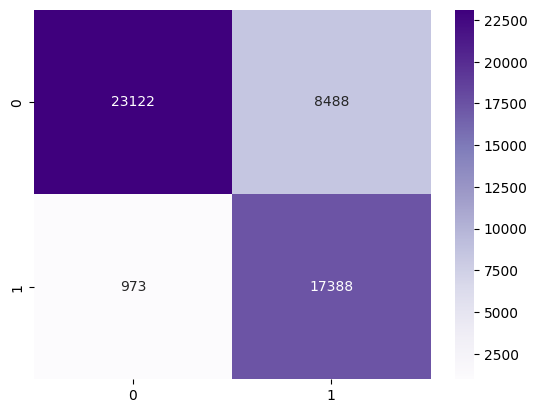

In [48]:
matriz_confusao_2 = confusion_matrix(y_teste, y_predicao_binaria_2)
sns.heatmap(matriz_confusao_2, annot=True, fmt='d', cmap='Purples')

##### 8.1.2. Relatório de Classificação
---

In [49]:
relatorio_classificacao_2 = classification_report(y_teste, y_predicao_binaria_2)
print(relatorio_classificacao_2)

              precision    recall  f1-score   support

         0.0       0.96      0.73      0.83     31610
         1.0       0.67      0.95      0.79     18361

    accuracy                           0.81     49971
   macro avg       0.82      0.84      0.81     49971
weighted avg       0.85      0.81      0.81     49971



##### 8.1.3. Curva ROC-AUC
---

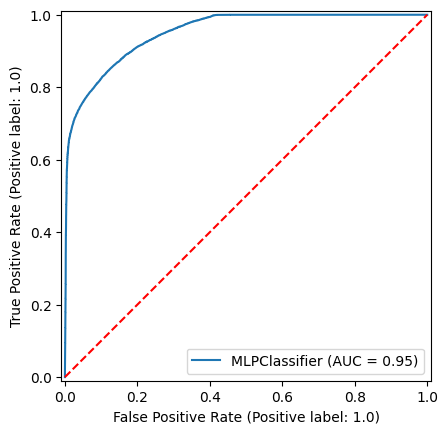

In [50]:
pg.gerar_roc_auc(modelo_campeao_rfe, X_teste_reduzido_df, y_teste)

##### 8.1.4. Curva Precision-Recall
---

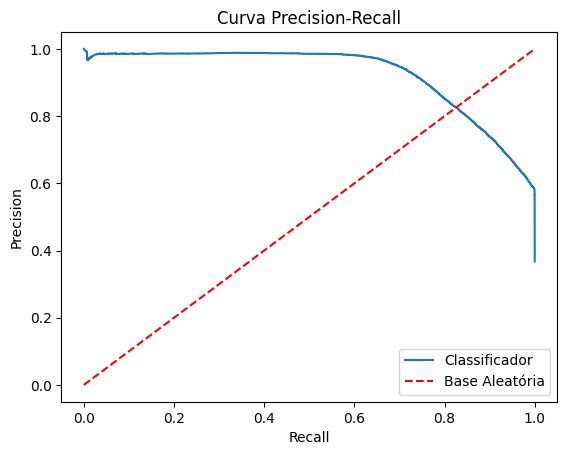

In [51]:
pg.gerar_curva_pr(y_teste, y_predicao_probabilistica_2)

In [52]:
pm.imprimir_prt(y_teste, y_predicao_probabilistica_2, obj_recall=True, meta_recall=0.95, obj_precision=True, meta_precision=0.95, obj_f1=True)


 - Objetivo focado em Recall (meta = 95.0%)
      Limiar ideal a ser usado: 0.4870
      Recall real obtido: 95.00% (Ataques detectados)
      Precision real obtida: 66.66% (Acerto dos alertas disparados)

 - Objetivo focado em Precision (meta >= 95.0%)
      Limiar ideal a ser usado: 0.9117
      Recall real obtido: 69.59% (Ataques detectados)
      Precision real obtida: 95.00% (Acerto dos alertas disparados)

 - Equilíbrio Simétrico (Max F1-Score)
      Limiar ideal: 0.7377
      Recall neste ponto: 82.85% (Ataques detectados)
      Precision neste ponto: 82.39% (Acerto dos alertas)


##### 8.1.5. Curva de Aprendizado
---

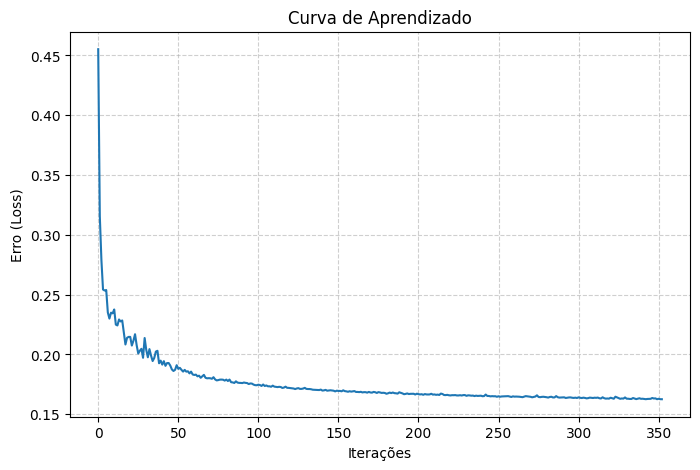

In [53]:
pg.gerar_curva_aprendizado(modelo_campeao_rfe)

#### 8.2. Limiar Equilibrado
---

##### 8.2.1. Matriz de Confusão
---

Limiar de equilíbrio do F1-Score entre Recall e Precision:

In [54]:
_, limiar_modelo_campeao_rfe, _ = pm.extrair_f1(y_teste, y_predicao_probabilistica_2)
print(limiar_modelo_campeao_rfe)

0.737683583512466


In [55]:
y_predicao_probabilistica_equilibrada_2 = (y_predicao_probabilistica_2 > limiar_modelo_campeao_rfe).astype(int)

<Axes: >

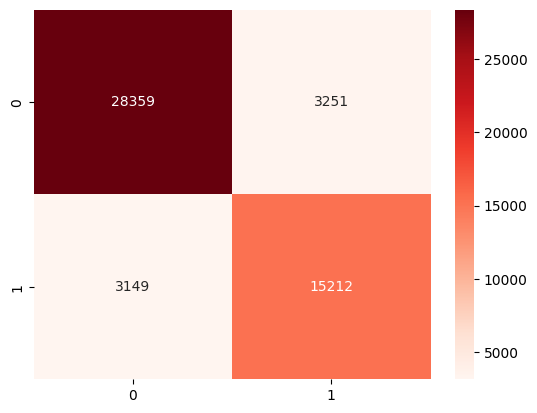

In [56]:
matriz_confusao_equilibrada_2 = confusion_matrix(y_teste, y_predicao_probabilistica_equilibrada_2)
sns.heatmap(matriz_confusao_equilibrada_2, annot=True, fmt='d', cmap='Reds')

##### 8.2.2. Relatório de Classificação
---

In [57]:
relatorio_classificacao_equilibrado_2 = classification_report(y_teste, y_predicao_probabilistica_equilibrada_2)
print(relatorio_classificacao_equilibrado_2)

              precision    recall  f1-score   support

         0.0       0.90      0.90      0.90     31610
         1.0       0.82      0.83      0.83     18361

    accuracy                           0.87     49971
   macro avg       0.86      0.86      0.86     49971
weighted avg       0.87      0.87      0.87     49971



## F) Comparando os Modelos Campeões
---

### 1. Desempenho dos modelos
---

In [58]:
print('\nComparação entre os modelos campeões a partir de Precision, Recall e F1-Score das Classes 0 e 1:\n')

print('\n1. MODELO CAMPEÃO SEM RFE:')
print('\n - Padrão:\n')
pm.imprimir_desempenho_modelo(matriz_confusao_1)
print('\n - Equilibrado:\n')
pm.imprimir_desempenho_modelo(matriz_confusao_equilibrada_1)

print('\n\n2. MODELO CAMPEÃO COM RFE:')
print('\n - Padrão:\n')
pm.imprimir_desempenho_modelo(matriz_confusao_2)
print('\n - Equilibrado:\n')
pm.imprimir_desempenho_modelo(matriz_confusao_equilibrada_2)



Comparação entre os modelos campeões a partir de Precision, Recall e F1-Score das Classes 0 e 1:


1. MODELO CAMPEÃO SEM RFE:

 - Padrão:

O total de predições de teste foi 49971.


 -> Classe 0:
    - Verdadeiro Negativo (TN): há 23198 casos, o que representa, aproximadamente, 46.42% do total de predições de teste.
    - Falso Negativo (FN): há 998 casos, o que representa, aproximadamente, 2.00% do total de predições de teste.

 -> Classe 1:
   - Verdadeiro Positivo (TP): há 17363 casos, o que representa, aproximadamente, 34.75% do total de predições de teste.
   - Falso Positivo (FP): há 8412 casos, o que representa, aproximadamente, 16.83% do total de predições de teste.


 -> Resultados Gerais:
    - A Acurácia total do modelo se dá por: (tp + tn) / total. Seu valor é 0.8117.
    - A quantidade de vezes que o modelo acertou é expressa por TN + TP e é igual a 40561, de um total de 49971. Corresponde a, aproximadamente, 81.17% das predições.
    - A quantidade de vezes que o modelo 

### 2. Diferenças entre os desempenhos
---

In [59]:
# Modelo campeão sem RFE
dados_modelo_1 = pm.extracao_desempenho_modelo(matriz_confusao_1)
dados_modelo_equilibrado_1 = pm.extracao_desempenho_modelo(matriz_confusao_equilibrada_1)

# Modelo campeão com RFE
dados_modelo_2 = pm.extracao_desempenho_modelo(matriz_confusao_2)
dados_modelo_equilibrado_2 = pm.extracao_desempenho_modelo(matriz_confusao_equilibrada_2)

# Total de registros
total_registros = dados_modelo_1['tn'] + dados_modelo_1['tp'] + dados_modelo_1['fn'] + dados_modelo_1['fp']

In [60]:
print('A) As diferenças métricas entre os modelos são:\n')
print('Nota: Valores de diferença ou percentual positivos indicam que o primeiro modelo/limiar apresenta resultados maiores que o segundo. Valores negativos indicam o oposto (o segundo termo possui valores maiores).')

print('\n1. Limiar Padrão:')
print('\n - Métricas Básicas:')
print(f'    TN: Sem RFE - {dados_modelo_1["tn"]} | Com RFE - {dados_modelo_2["tn"]} -> Diferença de {dados_modelo_1["tn"] - dados_modelo_2["tn"]} ou {pm.calcular_percentual((dados_modelo_1["tn"] - dados_modelo_2["tn"]), total_registros):.2f}%')
print(f'    TP: Sem RFE - {dados_modelo_1["tp"]} | Com RFE - {dados_modelo_2["tp"]} -> Diferença de {dados_modelo_1["tp"] - dados_modelo_2["tp"]} ou {pm.calcular_percentual((dados_modelo_1["tp"] - dados_modelo_2["tp"]), total_registros):.2f}%')
print(f'    FN: Sem RFE - {dados_modelo_1["fn"]} | Com RFE - {dados_modelo_2["fn"]} -> Diferença de {dados_modelo_1["fn"] - dados_modelo_2["fn"]} ou {pm.calcular_percentual((dados_modelo_1["fn"] - dados_modelo_2["fn"]), total_registros):.2f}%')
print(f'    FP: Sem RFE - {dados_modelo_1["fp"]} | Com RFE - {dados_modelo_2["fp"]} -> Diferença de {dados_modelo_1["fp"] - dados_modelo_2["fp"]} ou {pm.calcular_percentual((dados_modelo_1["fp"] - dados_modelo_2["fp"]), total_registros):.2f}%')

print('\n - Acurácia Geral do Modelo:')
print(f'    Acurácia: Sem RFE - {dados_modelo_1["accuracy"]} | Com RFE - {dados_modelo_2["accuracy"]} -> Diferença de {round(dados_modelo_1["accuracy"] - dados_modelo_2["accuracy"], 4)} ou {pm.calcular_percentual(dados_modelo_1["accuracy"] - dados_modelo_2["accuracy"], 1):.2f}%')

print('\n - Métricas por Classe:')
print(f'    Recall (0): Sem RFE - {dados_modelo_1["classe_0"]["recall"]} | Com RFE - {dados_modelo_2["classe_0"]["recall"]} -> Diferença de {round(dados_modelo_1["classe_0"]["recall"] - dados_modelo_2["classe_0"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["recall"] - dados_modelo_2["classe_0"]["recall"], 1):.2f}%')
print(f'    Recall(1): Sem RFE - {dados_modelo_1["classe_1"]["recall"]} | Com RFE - {dados_modelo_2["classe_1"]["recall"]} -> Diferença de {round(dados_modelo_1["classe_1"]["recall"] - dados_modelo_2["classe_1"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["recall"] - dados_modelo_2["classe_1"]["recall"], 1):.2f}%')
print(f'\n    Precision(0): Sem RFE - {dados_modelo_1["classe_0"]["precision"]} | Com RFE - {dados_modelo_2["classe_0"]["precision"]} -> Diferença de {round(dados_modelo_1["classe_0"]["precision"] - dados_modelo_2["classe_0"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["precision"] - dados_modelo_2["classe_0"]["precision"], 1):.2f}%')
print(f'    Precision(1): Sem RFE - {dados_modelo_1["classe_1"]["precision"]} | Com RFE - {dados_modelo_2["classe_1"]["precision"]} -> Diferença de {round(dados_modelo_1["classe_1"]["precision"] - dados_modelo_2["classe_1"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["precision"] - dados_modelo_2["classe_1"]["precision"], 1):.2f}%')
print(f'\n    F1-Score(0): Sem RFE - {dados_modelo_1["classe_0"]["f1_score"]} | Com RFE - {dados_modelo_2["classe_0"]["f1_score"]} -> Diferença de {round(dados_modelo_1["classe_0"]["f1_score"] - dados_modelo_2["classe_0"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["f1_score"] - dados_modelo_2["classe_0"]["f1_score"], 1):.2f}%')
print(f'    F1-Score(1): Sem RFE - {dados_modelo_1["classe_1"]["f1_score"]} | Com RFE - {dados_modelo_2["classe_1"]["f1_score"]} -> Diferença de {round(dados_modelo_1["classe_1"]["f1_score"] - dados_modelo_2["classe_1"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["f1_score"] - dados_modelo_2["classe_1"]["f1_score"], 1):.2f}%')

print('\n2. Limiar Equilibrado:')
print('\n - Métricas Básicas:')
print(f'    TN: Sem RFE - {dados_modelo_equilibrado_1["tn"]} | Com RFE - {dados_modelo_equilibrado_2["tn"]} -> Diferença de {dados_modelo_equilibrado_1["tn"] - dados_modelo_equilibrado_2["tn"]} ou {pm.calcular_percentual((dados_modelo_equilibrado_1["tn"] - dados_modelo_equilibrado_2["tn"]), total_registros):.2f}%')
print(f'    TP: Sem RFE - {dados_modelo_equilibrado_1["tp"]} | Com RFE - {dados_modelo_equilibrado_2["tp"]} -> Diferença de {dados_modelo_equilibrado_1["tp"] - dados_modelo_equilibrado_2["tp"]} ou {pm.calcular_percentual((dados_modelo_equilibrado_1["tp"] - dados_modelo_equilibrado_2["tp"]), total_registros):.2f}%')
print(f'    FN: Sem RFE - {dados_modelo_equilibrado_1["fn"]} | Com RFE - {dados_modelo_equilibrado_2["fn"]} -> Diferença de {dados_modelo_equilibrado_1["fn"] - dados_modelo_equilibrado_2["fn"]} ou {pm.calcular_percentual((dados_modelo_equilibrado_1["fn"] - dados_modelo_equilibrado_2["fn"]), total_registros):.2f}%')
print(f'    FP: Sem RFE - {dados_modelo_equilibrado_1["fp"]} | Com RFE - {dados_modelo_equilibrado_2["fp"]} -> Diferença de {dados_modelo_equilibrado_1["fp"] - dados_modelo_equilibrado_2["fp"]} ou {pm.calcular_percentual((dados_modelo_equilibrado_1["fp"] - dados_modelo_equilibrado_2["fp"]), total_registros):.2f}%')

print('\n - Acurácia Geral do Modelo:')
print(f'    Acurácia: Sem RFE - {dados_modelo_equilibrado_1["accuracy"]} | Com RFE - {dados_modelo_equilibrado_2["accuracy"]} -> Diferença de {round(dados_modelo_equilibrado_1["accuracy"] - dados_modelo_equilibrado_2["accuracy"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["accuracy"] - dados_modelo_equilibrado_2["accuracy"], 1):.2f}%')

print('\n - Métricas por Classe:')
print(f'    Recall (0): Sem RFE - {dados_modelo_equilibrado_1["classe_0"]["recall"]} | Com RFE - {dados_modelo_equilibrado_2["classe_0"]["recall"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_0"]["recall"] - dados_modelo_equilibrado_2["classe_0"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_0"]["recall"] - dados_modelo_equilibrado_2["classe_0"]["recall"], 1):.2f}%')
print(f'    Recall (1): Sem RFE - {dados_modelo_equilibrado_1["classe_1"]["recall"]} | Com RFE - {dados_modelo_equilibrado_2["classe_1"]["recall"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_1"]["recall"] - dados_modelo_equilibrado_2["classe_1"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_1"]["recall"] - dados_modelo_equilibrado_2["classe_1"]["recall"], 1):.2f}%')
print(f'\n    Precision (0): Sem RFE - {dados_modelo_equilibrado_1["classe_0"]["precision"]} | Com RFE - {dados_modelo_equilibrado_2["classe_0"]["precision"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_0"]["precision"] - dados_modelo_equilibrado_2["classe_0"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_0"]["precision"] - dados_modelo_equilibrado_2["classe_0"]["precision"], 1):.2f}%')
print(f'    Precision (1): Sem RFE - {dados_modelo_equilibrado_1["classe_1"]["precision"]} | Com RFE - {dados_modelo_equilibrado_2["classe_1"]["precision"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_1"]["precision"] - dados_modelo_equilibrado_2["classe_1"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_1"]["precision"] - dados_modelo_equilibrado_2["classe_1"]["precision"], 1):.2f}%')
print(f'\n    F1-Score (0): Sem RFE - {dados_modelo_equilibrado_1["classe_0"]["f1_score"]} | Com RFE - {dados_modelo_equilibrado_2["classe_0"]["f1_score"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_0"]["f1_score"] - dados_modelo_equilibrado_2["classe_0"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_0"]["f1_score"] - dados_modelo_equilibrado_2["classe_0"]["f1_score"], 1):.2f}%')
print(f'    F1-Score (1): Sem RFE - {dados_modelo_equilibrado_1["classe_1"]["f1_score"]} | Com RFE - {dados_modelo_equilibrado_2["classe_1"]["f1_score"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_1"]["f1_score"] - dados_modelo_equilibrado_2["classe_1"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_1"]["f1_score"] - dados_modelo_equilibrado_2["classe_1"]["f1_score"], 1):.2f}%')

print('\n')
print('-'*220)
print('\n')

print('\nB) As diferenças métricas entre os limiares dos modelos são:\n')
print('\n1. Modelo sem RFE:')
print('\n - Métricas Básicas:')
print(f'    TN: Padrão - {dados_modelo_1["tn"]} | Equilibrado - {dados_modelo_equilibrado_1["tn"]} -> Diferença de {dados_modelo_1["tn"] - dados_modelo_equilibrado_1["tn"]} ou {pm.calcular_percentual((dados_modelo_1["tn"] - dados_modelo_equilibrado_1["tn"]), total_registros):.2f}%')
print(f'    TP: Padrão - {dados_modelo_1["tp"]} | Equilibrado - {dados_modelo_equilibrado_1["tp"]} -> Diferença de {dados_modelo_1["tp"] - dados_modelo_equilibrado_1["tp"]} ou {pm.calcular_percentual((dados_modelo_1["tp"] - dados_modelo_equilibrado_1["tp"]), total_registros):.2f}%')
print(f'    FN: Padrão - {dados_modelo_1["fn"]} | Equilibrado - {dados_modelo_equilibrado_1["fn"]} -> Diferença de {dados_modelo_1["fn"] - dados_modelo_equilibrado_1["fn"]} ou {pm.calcular_percentual((dados_modelo_1["fn"] - dados_modelo_equilibrado_1["fn"]), total_registros):.2f}%')
print(f'    FP: Padrão - {dados_modelo_1["fp"]} | Equilibrado - {dados_modelo_equilibrado_1["fp"]} -> Diferença de {dados_modelo_1["fp"] - dados_modelo_equilibrado_1["fp"]} ou {pm.calcular_percentual((dados_modelo_1["fp"] - dados_modelo_equilibrado_1["fp"]), total_registros):.2f}%')

print('\n - Acurácia Geral do Modelo:')
print(f'    Acurácia: Padrão - {dados_modelo_1["accuracy"]} | Equilibrado - {dados_modelo_equilibrado_1["accuracy"]} -> Diferença de {round(dados_modelo_1["accuracy"] - dados_modelo_equilibrado_1["accuracy"], 4)} ou {pm.calcular_percentual(dados_modelo_1["accuracy"] - dados_modelo_equilibrado_1["accuracy"], 1):.2f}%')

print('\n - Métricas por Classe:')
print(f'    Recall (0): Padrão - {dados_modelo_1["classe_0"]["recall"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_0"]["recall"]} -> Diferença de {round(dados_modelo_1["classe_0"]["recall"] - dados_modelo_equilibrado_1["classe_0"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["recall"] - dados_modelo_equilibrado_1["classe_0"]["recall"], 1):.2f}%')
print(f'    Recall (1): Padrão - {dados_modelo_1["classe_1"]["recall"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_1"]["recall"]} -> Diferença de {round(dados_modelo_1["classe_1"]["recall"] - dados_modelo_equilibrado_1["classe_1"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["recall"] - dados_modelo_equilibrado_1["classe_1"]["recall"], 1):.2f}%')
print(f'\n    Precision (0): Padrão - {dados_modelo_1["classe_0"]["precision"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_0"]["precision"]} -> Diferença de {round(dados_modelo_1["classe_0"]["precision"] - dados_modelo_equilibrado_1["classe_0"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["precision"] - dados_modelo_equilibrado_1["classe_0"]["precision"], 1):.2f}%')
print(f'    Precision (1): Padrão - {dados_modelo_1["classe_1"]["precision"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_1"]["precision"]} -> Diferença de {round(dados_modelo_1["classe_1"]["precision"] - dados_modelo_equilibrado_1["classe_1"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["precision"] - dados_modelo_equilibrado_1["classe_1"]["precision"], 1):.2f}%')
print(f'\n    F1-Score (0): Padrão - {dados_modelo_1["classe_0"]["f1_score"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_0"]["f1_score"]} -> Diferença de {round(dados_modelo_1["classe_0"]["f1_score"] - dados_modelo_equilibrado_1["classe_0"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["f1_score"] - dados_modelo_equilibrado_1["classe_0"]["f1_score"], 1):.2f}%')
print(f'    F1-Score (1): Padrão - {dados_modelo_1["classe_1"]["f1_score"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_1"]["f1_score"]} -> Diferença de {round(dados_modelo_1["classe_1"]["f1_score"] - dados_modelo_equilibrado_1["classe_1"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["f1_score"] - dados_modelo_equilibrado_1["classe_1"]["f1_score"], 1):.2f}%')

print('\n2. Modelo com RFE:')
print('\n - Métricas Básicas:')
print(f'    TN: Padrão - {dados_modelo_2["tn"]} | Equilibrado - {dados_modelo_equilibrado_2["tn"]} -> Diferença de {dados_modelo_2["tn"] - dados_modelo_equilibrado_2["tn"]} ou {pm.calcular_percentual((dados_modelo_2["tn"] - dados_modelo_equilibrado_2["tn"]), total_registros):.2f}%')
print(f'    TP: Padrão - {dados_modelo_2["tp"]} | Equilibrado - {dados_modelo_equilibrado_2["tp"]} -> Diferença de {dados_modelo_2["tp"] - dados_modelo_equilibrado_2["tp"]} ou {pm.calcular_percentual((dados_modelo_2["tp"] - dados_modelo_equilibrado_2["tp"]), total_registros):.2f}%')
print(f'    FN: Padrão - {dados_modelo_2["fn"]} | Equilibrado - {dados_modelo_equilibrado_2["fn"]} -> Diferença de {dados_modelo_2["fn"] - dados_modelo_equilibrado_2["fn"]} ou {pm.calcular_percentual((dados_modelo_2["fn"] - dados_modelo_equilibrado_2["fn"]), total_registros):.2f}%')
print(f'    FP: Padrão - {dados_modelo_2["fp"]} | Equilibrado - {dados_modelo_equilibrado_2["fp"]} -> Diferença de {dados_modelo_2["fp"] - dados_modelo_equilibrado_2["fp"]} ou {pm.calcular_percentual((dados_modelo_2["fp"] - dados_modelo_equilibrado_2["fp"]), total_registros):.2f}%')

print('\n - Acurácia Geral do Modelo:')
print(f'    Acurácia: Padrão - {dados_modelo_2["accuracy"]} | Equilibrado - {dados_modelo_equilibrado_2["accuracy"]} -> Diferença de {round(dados_modelo_2["accuracy"] - dados_modelo_equilibrado_2["accuracy"], 4)} ou {pm.calcular_percentual(dados_modelo_2["accuracy"] - dados_modelo_equilibrado_2["accuracy"], 1):.2f}%')

print('\n - Métricas por Classe:')
print(f'    Recall (0): Padrão - {dados_modelo_2["classe_0"]["recall"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_0"]["recall"]} -> Diferença de {round(dados_modelo_2["classe_0"]["recall"] - dados_modelo_equilibrado_2["classe_0"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_0"]["recall"] - dados_modelo_equilibrado_2["classe_0"]["recall"], 1):.2f}%')
print(f'    Recall (1): Padrão - {dados_modelo_2["classe_1"]["recall"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_1"]["recall"]} -> Diferença de {round(dados_modelo_2["classe_1"]["recall"] - dados_modelo_equilibrado_2["classe_1"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_1"]["recall"] - dados_modelo_equilibrado_2["classe_1"]["recall"], 1):.2f}%')
print(f'    Precision (0): Padrão - {dados_modelo_2["classe_0"]["precision"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_0"]["precision"]} -> Diferença de {round(dados_modelo_2["classe_0"]["precision"] - dados_modelo_equilibrado_2["classe_0"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_0"]["precision"] - dados_modelo_equilibrado_2["classe_0"]["precision"], 1):.2f}%')
print(f'    Precision (1): Padrão - {dados_modelo_2["classe_1"]["precision"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_1"]["precision"]} -> Diferença de {round(dados_modelo_2["classe_1"]["precision"] - dados_modelo_equilibrado_2["classe_1"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_1"]["precision"] - dados_modelo_equilibrado_2["classe_1"]["precision"], 1):.2f}%')
print(f'    F1-Score (0): Padrão - {dados_modelo_2["classe_0"]["f1_score"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_0"]["f1_score"]} -> Diferença de {round(dados_modelo_2["classe_0"]["f1_score"] - dados_modelo_equilibrado_2["classe_0"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_0"]["f1_score"] - dados_modelo_equilibrado_2["classe_0"]["f1_score"], 1):.2f}%')
print(f'    F1-Score (1): Padrão - {dados_modelo_2["classe_1"]["f1_score"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_1"]["f1_score"]} -> Diferença de {round(dados_modelo_2["classe_1"]["f1_score"] - dados_modelo_equilibrado_2["classe_1"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_1"]["f1_score"] - dados_modelo_equilibrado_2["classe_1"]["f1_score"], 1):.2f}%')

A) As diferenças métricas entre os modelos são:

Nota: Valores de diferença ou percentual positivos indicam que o primeiro modelo/limiar apresenta resultados maiores que o segundo. Valores negativos indicam o oposto (o segundo termo possui valores maiores).

1. Limiar Padrão:

 - Métricas Básicas:
    TN: Sem RFE - 23198 | Com RFE - 23122 -> Diferença de 76 ou 0.15%
    TP: Sem RFE - 17363 | Com RFE - 17388 -> Diferença de -25 ou -0.05%
    FN: Sem RFE - 998 | Com RFE - 973 -> Diferença de 25 ou 0.05%
    FP: Sem RFE - 8412 | Com RFE - 8488 -> Diferença de -76 ou -0.15%

 - Acurácia Geral do Modelo:
    Acurácia: Sem RFE - 0.8117 | Com RFE - 0.8107 -> Diferença de 0.001 ou 0.10%

 - Métricas por Classe:
    Recall (0): Sem RFE - 0.7339 | Com RFE - 0.7315 -> Diferença de 0.0024 ou 0.24%
    Recall(1): Sem RFE - 0.9456 | Com RFE - 0.947 -> Diferença de -0.0014 ou -0.14%

    Precision(0): Sem RFE - 0.9588 | Com RFE - 0.9596 -> Diferença de -0.0008 ou -0.08%
    Precision(1): Sem RFE - 0.

## G) Persisitindo os Modelos
---

### 1. Primeiro modelo - Modelo campeão, sem RFE
---

In [61]:
joblib.dump(modelo_campeao, '../persistencia/modelos_persistentes/mlp/mlp_2c/mlp_2c.pkl')

['../persistencia/modelos_persistentes/mlp/mlp_2c/mlp_2c.pkl']

### 2. Segundo modelo - Modelo campeão, com RFE
---

In [62]:
joblib.dump(modelo_campeao_rfe, '../persistencia/modelos_persistentes/mlp/mlp_2c/mlp_2c_rfe.pkl')

['../persistencia/modelos_persistentes/mlp/mlp_2c/mlp_2c_rfe.pkl']